# Hipótesis 2: Análisis de Sobreprecio y Eficiencia por Demarcación

**La Hipótesis:**
El mercado de fichajes suele inflar desproporcionadamente el precio de ciertas demarcaciones (especialmente los atacantes) debido a su impacto directo en el gol y su atractivo mediático. Nuestra hipótesis plantea que **podemos identificar qué posiciones sufren un mayor 'sobreprecio' analizando el coste medio de los jugadores dentro de cada cuartil de mercado, en relación a su producción ofensiva real (Goles y Asistencias por 90 minutos).**

A través de este análisis, buscamos demostrar que, dentro de un mismo rango de edad y competición, la inversión requerida para adquirir talento de élite varía drásticamente según la demarcación, lo que permite a las direcciones deportivas optimizar su presupuesto enfocándose en posiciones o perfiles donde el mercado está menos inflado.

**¿Qué vamos a llevar a cabo en este análisis?**
Para comprobar esta hipótesis, seguiremos los siguientes pasos:

1. **Cruce de Valor y Rendimiento:** Cruzaremos los datos de rendimiento detallado (FBref) con los valores de mercado económicos actuales (Transfermarkt) de cada jugador.
2. **Categorización Posicional:** Estandarizaremos las demarcaciones en grandes grupos (Atacantes, Mediocentros y Defensas) para facilitar la comparativa.
3. **Análisis de Coste y Producción Media:** Filtraremos a los jóvenes talentos (Sub-23) de una liga específica (ej. La Liga) y calcularemos tanto su precio medio como su producción ofensiva promediada a 90 minutos.
4. **Segmentación por Cuartiles de Precio:** Dividiremos el mercado en 4 estratos económicos (desde *Bajo Coste* hasta *Élite*) para cada demarcación.
5. **Visualización del Sobreprecio:** Generaremos un diagrama de barras segmentado por cuartiles que revelará de forma visual e inmediata las asimetrías de precios entre las distintas posiciones del campo.

## 1. Carga y Cruzado Inicial de Datos (Hipótesis 2)
En esta sección abordamos el análisis de sobreprecio en el mercado. Para ello, cargamos los datos de rendimiento de FBREF y la información global de jugadores de Transfermarkt. Extraemos las columnas clave (nombre, valor de mercado, edad) y realizamos un cruce (`merge`) para tener en un solo dataframe la liga, la edad exacta y el precio de cada jugador.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display, HTML

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

f_full = 'dataset_transfermarkt/players_data-2025_2026.csv'
f_players_tm = 'dataset_transfermarkt/players.csv'

try:
    df_fbref = pd.read_csv(f_full)
    df_players = pd.read_csv(f_players_tm)
    print("Archivos cargados correctamente.")
except Exception as e:
    print(f"Error cargando los archivos: {e}")

col_precio_tm = 'market_value_in_eur'
col_edad_tm = 'date_of_birth'

cols_a_extraer = ['name', col_precio_tm, col_edad_tm]
df_players_sub = df_players[cols_a_extraer].drop_duplicates(subset=['name'])

df_val_merged = pd.merge(df_fbref, df_players_sub, left_on='Player', right_on='name', how='inner')
print(f"Jugadores cruzados con éxito: {len(df_val_merged)}")

Archivos cargados correctamente.
Jugadores cruzados con éxito: 2452


## 2. Categorización de Demarcaciones y Cálculo de Edades
Para facilitar el análisis del mercado, estandarizamos las múltiples posiciones que indica FBREF agrupándolas en 4 grandes bloques ('Atacantes', 'Mediocentros', 'Defensas' y 'Porteros'). Además, calculamos o extraemos la edad final del jugador a partir de su año de nacimiento.

In [2]:
def categorizar_posicion(pos):
    if pd.isna(pos): return 'Otro'
    if 'FW' in pos: return 'Atacantes (FW)'
    elif 'MF' in pos: return 'Mediocentros (MF)'
    elif 'DF' in pos: return 'Defensas (DF)'
    else: return 'Porteros (GK)'

df_val_merged['Demarcacion'] = df_val_merged['Pos'].apply(categorizar_posicion)

if 'Age' in df_val_merged.columns:
    df_val_merged['edad_final'] = pd.to_numeric(df_val_merged['Age'], errors='coerce')
elif col_edad_tm in df_val_merged.columns:
    df_val_merged['edad_final'] = 2026 - pd.to_datetime(df_val_merged['date_of_birth'], errors='coerce').dt.year
else:
    df_val_merged['edad_final'] = 25

df_val_merged['edad_final'] = df_val_merged['edad_final'].fillna(25)

print("Categorización completada. Muestra preliminar:")
display(df_val_merged[['Player', 'Comp', 'Demarcacion', 'edad_final', col_precio_tm]].head())

Categorización completada. Muestra preliminar:


,Player,Comp,Demarcacion,edad_final,market_value_in_eur
0,Brenden Aaronson,eng Premier League,Atacantes (FW),24.0,22000000.0
1,Jerome Abbey,eng Premier League,Mediocentros (MF),15.0,NaN
2,Zach Abbott,eng Premier League,Defensas (DF),19.0,4000000.0
3,Jones El-Abdellaoui,es La Liga,Atacantes (FW),19.0,8000000.0
4,Himad Abdelli,fr Ligue 1,Mediocentros (MF),25.0,5000000.0


## 3. Aplicación de Filtros de Mercado y Coste Medio
Definimos nuestra liga objetivo (por ejemplo, 'es La Liga') y un filtro de edad para encontrar 'Jóvenes Promesas' (ej. Sub-23). Excluímos a los porteros por tener dinámicas de mercado distintas y calculamos el Valor Medio y la Producción Ofensiva Media (Goles + Asistencias por 90 min) de cada demarcación.

In [3]:
liga_seleccionada = 'es La Liga'
edad_maxima = 23

df_analisis = df_val_merged[
    (df_val_merged['Comp'] == liga_seleccionada) &
    (df_val_merged['Demarcacion'] != 'Porteros (GK)') & 
    (df_val_merged['Min'] >= 500) &
    (df_val_merged['edad_final'] <= edad_maxima)
].copy()

df_analisis['Valor_Mundo_M'] = df_analisis[col_precio_tm] / 1e6

print(f"Coste Medio por Demarcación en {liga_seleccionada} (Jugadores de hasta {edad_maxima} años):\n")

resumen_dem = df_analisis.groupby('Demarcacion', observed=False).agg(
    Jugadores=('Player', 'count'),
    Valor_Medio_M=('Valor_Mundo_M', 'mean'),
    G_A_p90=('G+A', lambda x: (x / df_analisis.loc[x.index, '90s']).mean() if '90s' in df_analisis.columns else 0)
).reset_index().round(2)

resumen_dem.rename(columns={'Demarcacion': 'Demarcación', 'Jugadores': 'Nº Jugadores', 'Valor_Medio_M': 'Precio Medio (M€)', 'G_A_p90': 'Media G+A (p/90)'}, inplace=True)
display(resumen_dem)

Coste Medio por Demarcación en es La Liga (Jugadores de hasta 23 años):



,Demarcación,Nº Jugadores,Precio Medio (M€),Media G+A (p/90)
0,Atacantes (FW),29,19.26,0.36
1,Defensas (DF),33,18.15,0.08
2,Mediocentros (MF),36,25.58,0.24


## 4. Cuartiles de Precio y Visualización del Sobreprecio
Para entender la estructura de precios del mercado, dividimos los valores de mercado en 4 cuartiles: Económico, Medio-Bajo, Medio-Alto y Élite. Agrupamos los datos por demarcación y cuartil, y los graficamos en un diagrama de barras. Esto permite identificar rápidamente qué demarcaciones sufren un mayor sobreprecio en sus perfiles más cotizados.

Desglose de Cuartiles de Precio:


,Demarcación,Cuartil de Precio,Precio Mínimo (M€),Precio Máximo (M€),Precio Medio (M€),Nº Jugadores
0,Atacantes (FW),1 (Económico),0.3,3.5,2.27,6
1,Atacantes (FW),2 (Medio-Bajo),4.5,12.0,7.90,10
2,Atacantes (FW),3 (Medio-Alto),15.0,20.0,16.78,9
3,Atacantes (FW),4 (Élite),30.0,200.0,78.75,4
4,Defensas (DF),1 (Económico),0.2,4.0,2.36,12
5,Defensas (DF),2 (Medio-Bajo),7.5,12.0,10.12,4
6,Defensas (DF),3 (Medio-Alto),14.0,25.0,18.00,9
7,Defensas (DF),4 (Élite),28.0,80.0,46.00,8
8,Mediocentros (MF),1 (Económico),1.8,4.0,2.76,7
9,Mediocentros (MF),2 (Medio-Bajo),4.5,10.0,7.14,11


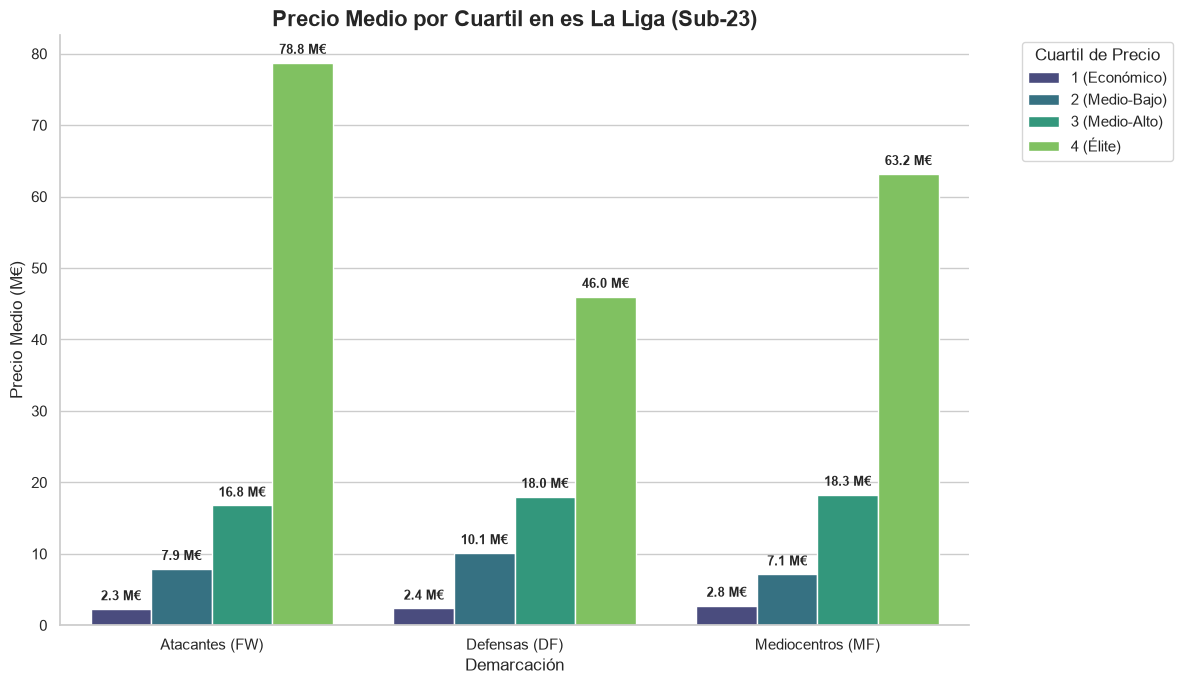

In [4]:
df_analisis['Cuartil_Precio'] = pd.qcut(df_analisis['Valor_Mundo_M'].fillna(0), 4, labels=['1 (Económico)', '2 (Medio-Bajo)', '3 (Medio-Alto)', '4 (Élite)'])

resumen_cuartiles = df_analisis.groupby(['Demarcacion', 'Cuartil_Precio'], observed=False).agg(
    Precio_Min=('Valor_Mundo_M', 'min'), 
    Precio_Max=('Valor_Mundo_M', 'max'), 
    Precio_Medio=('Valor_Mundo_M', 'mean'), 
    Total_Jugadores=('Player', 'count')
).reset_index().round(2)

resumen_cuartiles_display = resumen_cuartiles.rename(columns={'Demarcacion': 'Demarcación', 'Cuartil_Precio': 'Cuartil de Precio', 'Precio_Min': 'Precio Mínimo (M€)', 'Precio_Max': 'Precio Máximo (M€)', 'Precio_Medio': 'Precio Medio (M€)', 'Total_Jugadores': 'Nº Jugadores'})

print("Desglose de Cuartiles de Precio:")
display(resumen_cuartiles_display.head(10))

# Visualización
plt.figure(figsize=(12, 7))
ax = sns.barplot(data=resumen_cuartiles, x='Demarcacion', y='Precio_Medio', hue='Cuartil_Precio', palette='viridis')

plt.title(f"Precio Medio por Cuartil en {liga_seleccionada} (Sub-{edad_maxima})", fontsize=16, fontweight='bold')
plt.xlabel('Demarcación', fontsize=12)
plt.ylabel('Precio Medio (M€)', fontsize=12)

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(format(p.get_height(), '.1f') + ' M€', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha = 'center', va = 'center', 
                    xytext = (0, 9), 
                    textcoords = 'offset points',
                    fontweight='bold', fontsize=9)

plt.legend(title='Cuartil de Precio', bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()